# Simulador Hardy-Weinberg de Poniente

Simulación de poblaciones en equilibrio de Hardy-Weinberg para las casas de Poniente, con cruces entre casas y tests estadísticos.

**Contenido**

1. Imports
2. Clase abstracta `LocusHardyWeinberg`
3. Clase concreta `LocusEquilibrio`
4. Clase `DosLocus`
5. Clase `Casa`
6. Fábrica de casas `crear_casas()`
7. Cruces entre casas (descendencia F1)
8. Test chi-cuadrado: funciones auxiliares
9. Test chi-cuadrado de bondad de ajuste H-W
10. Test chi-cuadrado de independencia entre loci
11. Gráficos observado vs esperado
12. Demo principal

In [ ]:
# TIMBA de Tronos
''' Caracteres fenotípicos elegidos:
N : pelo negro
n : pelo rubio
r : pelo rojo
b : pelo blanco
M : pelo marrón
////////////////
C : ojos marrones
v : ojos verdes
a : ojos azules
t : ojos púrpura
////////////////

Son dos locus distintos
Ley Hardy-Weinberg:
1 = p^2 + 2*pq + q^2

////////////////
Casa Stark : M^2 + 2*Mr + r^2 = 1 // C^2 = 1
Casa Lannister : n^2 = 1 // a^2 = 1
Casa Targaryen : b^2 + 2*bN + N^2 = 1 // t^2 = 1
Casa Martell : v^2 + 2*vM + M^2 = 1 // b^2 = 1
Casa Targaryen (Blackfyre) : t^2 + 2*tv + v^2 = 1 //  b^2 + 2*bN + N^2 = 1 (Versión Dificil)
Casa Baratheon : N^2  = 1 // v^2 = 1
Casa Tyrell : n^2 + 2*nN + N^2 = 1 // a^2 = 1
Casa Hightower : r^2 + 2*rM + M^2 = 1 // C^2 = 1
////////////// '''

## 1. Imports

In [ ]:
import math
import numpy as np
from abc import ABC, abstractmethod

import matplotlib
matplotlib.use("Agg")                       # backend sin display
import matplotlib.pyplot as plt

## 2. Clase abstracta: un locus en equilibrio Hardy-Weinberg

Define la estructura común de un locus: frecuencias alélicas, probabilidades genotípicas y simulación multinomial. Las subclases deben implementar `_calcular_probabilidades()`.

In [ ]:
class LocusHardyWeinberg(ABC):
    """
    Clase abstracta que representa UN locus génico en equilibrio
    Hardy-Weinberg. Define la estructura común: frecuencias alélicas,
    probabilidades genotípicas y simulación multinomial.

    Las subclases concretas deben implementar _calcular_probabilidades(),
    que define cómo se obtienen las probabilidades genotípicas a partir
    de las frecuencias alélicas (la ley de H-W: p², 2pq, q², ...).
    """

    def __init__(self, nombre: str, frecuencias: dict, seed: int = None):
        """
        Constructor base (lo heredan todas las subclases).

        Parámetros:
            nombre (str): nombre del locus, p. ej. "Pelo" u "Ojos".
            frecuencias (dict): {alelo: frecuencia}, debe sumar 1.
            seed (int, opcional): semilla para reproducibilidad.
        """
        # --- Validaciones ---
        if not frecuencias:
            raise ValueError("El locus necesita al menos un alelo.")
        if any(f < 0 for f in frecuencias.values()):
            raise ValueError("Las frecuencias no pueden ser negativas.")
        if abs(sum(frecuencias.values()) - 1.0) > 1e-9:
            raise ValueError("Las frecuencias alélicas deben sumar 1.")

        # --- Atributos (propiedades de la instancia) ---
        self.nombre = nombre
        self.frecuencias = dict(frecuencias)   # frecuencias alélicas (teóricas)
        self.seed = seed

        # Generador aleatorio propio de cada instancia (buena práctica OOP)
        self.rng = np.random.default_rng(seed)

        # Se calculan al construir la instancia (propiedad derivada)
        self.prob_genotipicas = self._calcular_probabilidades()

    @property
    def alelos(self) -> list:
        """Lista de alelos del locus."""
        return list(self.frecuencias)

    @abstractmethod
    def _calcular_probabilidades(self) -> dict:
        """
        Método abstracto: cada subclase define aquí la ley de H-W
        que le corresponde. Debe devolver {genotipo: probabilidad}.
        """

    def simular(self, n: int) -> dict:
        """
        Simula n individuos para ESTE locus con una multinomial
        sobre los genotipos posibles.
        """
        genotipos = list(self.prob_genotipicas)
        probs = list(self.prob_genotipicas.values())
        conteos = self.rng.multinomial(n, probs)

        return {
            "conteos": dict(zip(genotipos, conteos)),
            "frec_obs": dict(zip(genotipos, conteos / n)),
            "frec_esp": self.prob_genotipicas,
        }

    def frecuencias_alelicas_observadas(self, conteos: dict) -> dict:
        """
        Reestima las frecuencias alélicas desde los conteos genotípicos:
        cada homocigoto aporta 2 copias, cada heterocigoto 1 por alelo.
        """
        total = sum(conteos.values()) * 2          # copias totales de alelos
        obs = {a: 0.0 for a in self.alelos}
        for gen, c in conteos.items():
            obs[gen[0]] += c
            obs[gen[1]] += c
        return {a: obs[a] / total for a in self.alelos}

## 3. Clase concreta: locus k-alélico en equilibrio H-W

Generaliza la ley de Hardy-Weinberg a k alelos. Con 2 alelos se reduce a p² + 2pq + q² = 1.

In [ ]:
class LocusEquilibrio(LocusHardyWeinberg):
    """
    Locus concreto con la ley de Hardy-Weinberg generalizada a k alelos:

        P(AiAi)   = pi²          (homocigotos)
        P(AiAj)   = 2 * pi * pj  (heterocigotos, i != j)

    Con 2 alelos se reduce exactamente a p² + 2pq + q² = 1.
    """

    def _calcular_probabilidades(self) -> dict:
        probs = {}
        alelos = self.alelos
        for i, a1 in enumerate(alelos):
            for j in range(i, len(alelos)):
                a2 = alelos[j]
                p = self.frecuencias[a1] * self.frecuencias[a2]
                p *= 2 if i != j else 1          # factor 2 del heterocigoto
                # Etiqueta del genotipo: alelo dominante (mayúscula) primero
                gen = a1 + a2 if i == j else "".join(
                    sorted([a1, a2], key=lambda x: (not x.isupper(), x)))
                probs[gen] = p
        return probs

## 4. Clase de dos loci

Combina dos loci independientes (sin ligamiento): la probabilidad conjunta es el producto de las marginales y la simulación es una multinomial sobre las k1 · k2 combinaciones.

In [ ]:
class DosLocus:
    """
    Combina dos loci en equilibrio Hardy-Weinberg bajo la hipótesis
    de independencia (no hay ligamiento génico).

    La probabilidad conjunta es el producto de las marginales:
        P(geno_pelo, geno_ojos) = P(geno_pelo) * P(geno_ojos)

    y la simulación de n individuos es una multinomial sobre las
    k1 * k2 combinaciones genotípicas posibles.
    """

    def __init__(self, locus_1: LocusHardyWeinberg, locus_2: LocusHardyWeinberg,
                 seed: int = None):
        self.locus_1 = locus_1
        self.locus_2 = locus_2
        self.rng = np.random.default_rng(seed)

        # Tabla de probabilidades conjuntas (producto de marginales)
        self.prob_conjunta = {
            f"{g1}-{g2}": p1 * p2
            for g1, p1 in locus_1.prob_genotipicas.items()
            for g2, p2 in locus_2.prob_genotipicas.items()
        }

    def simular(self, n: int) -> dict:
        """Simula n individuos a dos loci con una multinomial conjunta."""
        combos = list(self.prob_conjunta)
        probs = list(self.prob_conjunta.values())
        conteos_vec = self.rng.multinomial(n, probs)
        conteos = dict(zip(combos, conteos_vec))

        # Marginales por locus (sumando sobre el otro locus)
        def marginal(locus, idx):
            marg = {g: 0 for g in locus.prob_genotipicas}
            for combo, c in conteos.items():
                marg[combo.split("-")[idx]] += c
            return marg

        return {
            "conteos_conjunta": conteos,
            "marginal_locus_1": marginal(self.locus_1, 0),
            "marginal_locus_2": marginal(self.locus_2, 1),
        }

## 5. Clase Casa

Una casa de Poniente queda definida por las frecuencias alélicas de sus dos loci (pelo y ojos). Al instanciarla se crean los loci y el simulador de dos loci.

In [ ]:
class Casa:
    """
    Casa de Poniente definida por las frecuencias alélicas de sus dos
    loci fenotípicos (pelo y ojos). Al instanciarla se generan los
    dos loci y el simulador de dos loci, listos para usar.

    Uso:
        stark = Casa("Stark", frec_pelo={"M": 0.7, "r": 0.3},
                     frec_ojos={"C": 1.0}, seed=42)
        stark.simular(10_000)
    """

    def __init__(self, nombre: str, frec_pelo: dict, frec_ojos: dict,
                 seed: int = None):
        self.nombre = nombre
        self.locus_pelo = LocusEquilibrio("Pelo", frec_pelo, seed=seed)
        self.locus_ojos = LocusEquilibrio("Ojos", frec_ojos, seed=seed)
        self.genoma = DosLocus(self.locus_pelo, self.locus_ojos, seed=seed)

    def simular(self, n: int = 10_000) -> dict:
        """Simula n personas de la casa y devuelve el resultado a dos loci."""
        return self.genoma.simular(n)

    def mostrar(self, n: int = 10_000, top: int = 6) -> None:
        """Muestra frecuencias alélicas y los genotipos más frecuentes."""
        res = self.simular(n)
        print("=" * 60)
        print(f"  CASA {self.nombre.upper()}  (N = {n})")
        print("=" * 60)
        for locus, marg in ((self.locus_pelo, res["marginal_locus_1"]),
                            (self.locus_ojos, res["marginal_locus_2"])):
            obs = locus.frecuencias_alelicas_observadas(marg)
            teor = ", ".join(f"{a}: {f:.3f}" for a, f in locus.frecuencias.items())
            obss = ", ".join(f"{a}: {f:.3f}" for a, f in obs.items())
            print(f"  Locus {locus.nombre}: teórico {{{teor}}} | observado {{{obss}}}")
        ranking = sorted(res["conteos_conjunta"].items(),
                         key=lambda kv: -kv[1])[:top]
        print("  Genotipos (pelo-ojos) más frecuentes:")
        for gen, c in ranking:
            print(f"    {gen:8s}: {c:>6} ({c/n:.2%})")
        print()

## 6. Fábrica de casas

Crea las 8 casas con sus frecuencias alélicas. Las ecuaciones tipo M² + 2Mr + r² = 1 describen el equilibrio pero no fijan las frecuencias, por lo que hay que elegir p y q (ajustables en cada entrada).

In [ ]:
def crear_casas(seed: int = 42) -> dict:
    """
    Crea las instancias de cada Casa según las especificaciones.

    Nota: las ecuaciones tipo M² + 2Mr + r² = 1 describen el EQUILIBRIO
    pero no fijan las frecuencias: hay que elegir p y q (ajustables
    en cada entrada del diccionario).
    """
    specs = {
        "Stark": Casa("Stark", {"M": 0.7, "r": 0.3}, {"C": 1.0}, seed=seed),
        "Lannister": Casa("Lannister", {"n": 1.0}, {"a": 1.0}, seed=seed),
        "Targaryen": Casa("Targaryen", {"b": 0.6, "N": 0.4}, {"t": 1.0}, seed=seed),
        "Martell": Casa("Martell", {"v": 0.5, "M": 0.5}, {"C": 1.0}, seed=seed),
        "Blackfyre": Casa("Blackfyre", {"b": 0.5, "N": 0.5},
                          {"t": 0.5, "v": 0.5}, seed=seed),
        "Baratheon": Casa("Baratheon", {"N": 1.0}, {"v": 1.0}, seed=seed),
        "Tyrell": Casa("Tyrell", {"n": 0.5, "N": 0.5}, {"a": 1.0}, seed=seed),
        "Hightower": Casa("Hightower", {"r": 0.4, "M": 0.6}, {"C": 1.0}, seed=seed),
    }
    return specs

## 7. Cruces entre casas (descendencia F1)

Matrimonio entre dos casas: se calcula la distribución genotípica esperada de la F1 y se simula muestreando un gameto de cada progenitor.

- La frecuencia alélica en F1 es el promedio de las de los padres.
- Si las frecuencias parentales difieren, la F1 **no** está en equilibrio H-W (exceso de heterocigotos).
- Recién en la F2 (F1 × F1) se vuelve al equilibrio.

In [ ]:
def _etiqueta_genotipo(a1: str, a2: str) -> str:
    """Etiqueta canónica: alelo dominante (mayúscula) primero."""
    if a1 == a2:
        return a1 + a2
    return "".join(sorted([a1, a2], key=lambda x: (not x.isupper(), x)))

In [ ]:
class CruceEntreCasas:
    """
    Matrimonio entre dos casas. Calcula la distribución genotípica
    esperada en la descendencia (F1) y la simula muestreando gametos
    de cada progenitor.

    Genética de población (sin selección ni deriva, una generación):

      * Frecuencia alélica en F1 = promedio de las de los padres:
            p_F1(a) = (p_padre(a) + p_madre(a)) / 2

      * Pero la distribución genotípica de F1 NO es H-W cuando las
        frecuencias parentales difieren: hay exceso de heterocigotos
        en la F1 ("heterosis" de la primera generación). La
        probabilidad exacta, muestreando un gameto de cada padre, es:

            P(AiAi) = p_padre(Ai) * p_madre(Ai)
            P(AiAj) = p_padre(Ai) * p_madre(Aj)
                    + p_padre(Aj) * p_madre(Ai)

      * Recién a partir de la F2 (cruzando F1 x F1) vuelve al
        equilibrio H-W con p = promedio parental.
    """

    def __init__(self, padre: Casa, madre: Casa, seed: int = None):
        self.padre = padre
        self.madre = madre
        self.rng = np.random.default_rng(seed)

        self.loci = []           # [(nombre, locus_padre, locus_madre), ...]
        self.frec_f1 = {}        # {nombre_locus: {alelo: frec F1}}
        self.prob_f1 = {}        # {nombre_locus: {genotipo: prob exacta F1}}

        for nombre_l, l_p, l_m in (
                ("Pelo", padre.locus_pelo, madre.locus_pelo),
                ("Ojos", padre.locus_ojos, madre.locus_ojos)):
            self.loci.append((nombre_l, l_p, l_m))
            alelos = sorted(set(l_p.alelos) | set(l_m.alelos))
            self.frec_f1[nombre_l] = {
                a: (l_p.frecuencias.get(a, 0.0) + l_m.frecuencias.get(a, 0.0)) / 2
                for a in alelos}
            self.prob_f1[nombre_l] = self._distribucion_f1(l_p, l_m)

    @staticmethod
    def _distribucion_f1(l_p: LocusHardyWeinberg,
                         l_m: LocusHardyWeinberg) -> dict:
        """Distribución genotípica exacta de F1 (producto de gametos)."""
        alelos = sorted(set(l_p.alelos) | set(l_m.alelos))
        pf = {a: l_p.frecuencias.get(a, 0.0) for a in alelos}
        pm = {a: l_m.frecuencias.get(a, 0.0) for a in alelos}
        probs = {}
        for i, a1 in enumerate(alelos):
            for j in range(i, len(alelos)):
                a2 = alelos[j]
                if i == j:
                    p = pf[a1] * pm[a1]
                else:
                    p = pf[a1] * pm[a2] + pf[a2] * pm[a1]
                probs[_etiqueta_genotipo(a1, a2)] = p
        return probs

    def simular(self, n: int = 10_000) -> dict:
        """
        Simula n hijos muestreando un gameto de cada progenitor
        para cada locus.
        """
        hijos = {}
        for nombre_l, l_p, l_m in self.loci:
            alelos = sorted(set(l_p.alelos) | set(l_m.alelos))
            p_p = [l_p.frecuencias.get(a, 0.0) for a in alelos]
            p_m = [l_m.frecuencias.get(a, 0.0) for a in alelos]

            gam_p = self.rng.choice(alelos, size=n, p=p_p)
            gam_m = self.rng.choice(alelos, size=n, p=p_m)

            conteos = {}
            for g1, g2 in zip(gam_p, gam_m):
                gen = _etiqueta_genotipo(g1, g2)
                conteos[gen] = conteos.get(gen, 0) + 1

            hijos[nombre_l] = {
                "conteos": conteos,
                "frec_obs": {g: c / n for g, c in conteos.items()},
                "frec_esp": self.prob_f1[nombre_l],
                "frec_alelica_f1": self.frec_f1[nombre_l],
            }
        return hijos

    def mostrar(self, n: int = 10_000) -> None:
        res = self.simular(n)
        print("=" * 64)
        print(f"  CRUCE {self.padre.nombre.upper()} x {self.madre.nombre.upper()}"
              f"  (N = {n} hijos)")
        print("=" * 64)
        for nombre_l, _lp, _lm in self.loci:
            r = res[nombre_l]
            fa = ", ".join(f"{a}: {f:.3f}" for a, f in r["frec_alelica_f1"].items())
            print(f"  Locus {nombre_l} | frec. alélica F1: {{{fa}}}")
            gens = [g for g in r["frec_esp"] if r["frec_esp"][g] > 0]
            for gen in sorted(gens, key=lambda g: -r["frec_esp"][g]):
                obs = r["frec_obs"].get(gen, 0.0)
                print(f"    {gen:6s}: obs {obs:7.2%} | esp {r['frec_esp'][gen]:7.2%}")
        print()

In [ ]:
def cruzar(padre: Casa, madre: Casa, n: int = 10_000, seed: int = None) -> CruceEntreCasas:
    """Atajo: crea el cruce, lo simula y lo muestra por pantalla."""
    c = CruceEntreCasas(padre, madre, seed=seed)
    c.mostrar(n)
    return c

## 8. Test chi-cuadrado: funciones auxiliares

Función de supervivencia de la chi-cuadrado. Usa `scipy` si está disponible; si no, usa una implementación propia de la gamma incompleta.

In [ ]:
def _gser(a: float, x: float) -> float:
    """Gamma incompleta inferior regularizada (serie)."""
    gln = math.lgamma(a)
    ap, s, delta = a, 1.0 / a, 1.0 / a
    for _ in range(200):
        ap += 1
        delta *= x / ap
        s += delta
        if abs(delta) < abs(s) * 1e-12:
            break
    return s * np.exp(-x + a * np.log(x) - gln)


def _gcf(a: float, x: float) -> float:
    """Gamma incompleta superior regularizada (fracción continua)."""
    gln = math.lgamma(a)
    b, c = x + 1 - a, 1e300
    d = 1.0 / b
    h = d
    for i in range(1, 200):
        an = -i * (i - a)
        b += 2
        d = an * d + b
        if abs(d) < 1e-300:
            d = 1e-300
        c = b + an / c
        if abs(c) < 1e-300:
            c = 1e-300
        d = 1.0 / d
        delta = d * c
        h *= delta
        if abs(delta - 1.0) < 1e-12:
            break
    return np.exp(-x + a * np.log(x) - gln) * h


def _gammaincc(a: float, x: float) -> float:
    """Q(a, x) = 1 - P(a, x): cola superior de la gamma (fallback puro)."""
    if x < a + 1.0:
        return 1.0 - _gser(a, x)
    return _gcf(a, x)


def chi2_sf(x: float, df: int) -> float:
    """Función de supervivencia de la chi-cuadrado: P(X > x), X ~ chi2(df)."""
    if df <= 0:
        return 1.0
    try:
        from scipy.stats import chi2
        return float(chi2.sf(x, df))
    except ImportError:
        return float(_gammaincc(df / 2.0, x / 2.0))

## 9. Test chi-cuadrado de bondad de ajuste H-W

Se aplica a un locus, a una casa (ambos loci) y a un cruce (contra la distribución F1 exacta).

In [ ]:
def test_chi2_locus(locus: LocusHardyWeinberg, conteos: dict) -> dict:
    """
    Test chi-cuadrado de bondad de ajuste al equilibrio H-W.

        H0: los conteos genotípicos observados provienen de las
            probabilidades teóricas del locus (p², 2pq, q²).

    Grados de libertad = #genotipos - #alelos (las frecuencias
    alélicas se reestiman de los datos: k(k+1)/2 - k = k(k-1)/2).
    Si el locus es fijo (un solo genotipo), gl = 0 y no hay test.
    """
    n = sum(conteos.values())
    genotipos = list(locus.prob_genotipicas)
    obs = np.array([conteos.get(g, 0) for g in genotipos], dtype=float)
    esp = np.array([n * locus.prob_genotipicas[g] for g in genotipos])

    chi2_stat = float(((obs - esp) ** 2 / esp).sum())
    k = len(locus.alelos)
    gl = len(genotipos) - k

    if gl <= 0:
        return {"chi2": 0.0, "gl": 0, "p": 1.0,
                "veredicto": "locus fijo (sin test)"}

    p_valor = chi2_sf(chi2_stat, gl)
    veredicto = "No se rechaza H0 (ajusta a H-W)" if p_valor > 0.05 \
        else "Se rechaza H0 (NO ajusta, p < 0.05)"
    return {"chi2": chi2_stat, "gl": gl, "p": p_valor, "veredicto": veredicto}


def test_chi2_casa(casa: Casa, n: int = 10_000) -> list:
    """Aplica el test H-W a ambos loci de una casa simulada."""
    res = casa.simular(n)
    salida = []
    for locus, marg, key in ((casa.locus_pelo, res["marginal_locus_1"], "Pelo"),
                             (casa.locus_ojos, res["marginal_locus_2"], "Ojos")):
        t = test_chi2_locus(locus, marg)
        t["locus"] = f"{casa.nombre}/{key}"
        salida.append(t)
    return salida


def test_chi2_cruce(cruce: CruceEntreCasas, n: int = 10_000) -> list:
    """Compara los conteos de hijos simulados con la distribución F1 exacta."""
    res = cruce.simular(n)
    salida = []
    for nombre_l in res:
        conteos = res[nombre_l]["conteos"]
        # solo genotipos con esperanza positiva (los de prob. 0 no aportan)
        gens = [g for g in res[nombre_l]["frec_esp"] if res[nombre_l]["frec_esp"][g] > 0]
        obs = np.array([conteos.get(g, 0) for g in gens], dtype=float)
        esp = np.array([n * res[nombre_l]["frec_esp"][g] for g in gens])
        chi2_stat = float(((obs - esp) ** 2 / esp).sum())
        gl = len(gens) - 1          # las frec. parentales son parámetros fijos
        if gl <= 0:
            salida.append({"locus": f"{cruce.padre.nombre}x{cruce.madre.nombre}/{nombre_l}",
                           "chi2": 0.0, "gl": 0, "p": 1.0,
                           "veredicto": "F1 fija en este locus (sin test)"})
            continue
        p_valor = chi2_sf(chi2_stat, gl)
        veredicto = "No se rechaza H0 (ajusta a F1)" if p_valor > 0.05 \
            else "Se rechaza H0 (p < 0.05)"
        salida.append({"locus": f"{cruce.padre.nombre}x{cruce.madre.nombre}/{nombre_l}",
                       "chi2": chi2_stat, "gl": gl, "p": p_valor,
                       "veredicto": veredicto})
    return salida

## 10. Test chi-cuadrado de independencia entre loci

Tabla de contingencia sobre los conteos conjuntos. H0: los loci son independientes (no hay ligamiento). gl = (k1 − 1)(k2 − 1).

In [ ]:
def test_chi2_independencia(res_dos_locus: dict, locus_1: LocusHardyWeinberg,
                            locus_2: LocusHardyWeinberg) -> dict:
    """
    Test chi-cuadrado de independencia (tabla de contingencia) entre
    los dos loci a partir de los conteos conjuntos simulados.

        H0: los loci son independientes (no hay ligamiento).

    gl = (k1 - 1)(k2 - 1). Si algún locus es fijo, gl = 0 y no hay test.
    """
    g1 = list(locus_1.prob_genotipicas)
    g2 = list(locus_2.prob_genotipicas)
    obs = np.array([[res_dos_locus["conteos_conjunta"].get(f"{a}-{b}", 0)
                     for b in g2] for a in g1], dtype=float)
    n = obs.sum()
    esp = np.outer(obs.sum(axis=1), obs.sum(axis=0)) / n

    chi2_stat = float(((obs - esp) ** 2 / esp).sum())
    gl = (len(g1) - 1) * (len(g2) - 1)

    if gl <= 0:
        return {"chi2": 0.0, "gl": 0, "p": 1.0,
                "veredicto": "algún locus fijo (sin test)"}

    p_valor = chi2_sf(chi2_stat, gl)
    veredicto = "No se rechaza H0 (loci independientes)" if p_valor > 0.05 \
        else "Se rechaza H0 (posible ligamiento, p < 0.05)"
    return {"chi2": chi2_stat, "gl": gl, "p": p_valor, "veredicto": veredicto,
            "tabla_obs": obs, "genotipos_1": g1, "genotipos_2": g2}

## 11. Gráficos: barras observado vs esperado

In [ ]:
def graficar_locus(ax, titulo: str, genotipos: list, obs: np.ndarray,
                   esp: np.ndarray) -> None:
    """Barras agrupadas obs vs esp sobre un eje dado."""
    x = np.arange(len(genotipos))
    ancho = 0.38
    ax.bar(x - ancho / 2, obs, ancho, label="Observado", color="#7f9db9")
    ax.bar(x + ancho / 2, esp, ancho, label="Esperado", color="#c9a227")
    ax.set_xticks(x, genotipos)
    ax.set_title(titulo, fontsize=10)
    ax.legend(fontsize=8)
    ax.tick_params(axis="x", labelsize=8)
    ax.tick_params(axis="y", labelsize=8)


def graficar_casa(casa: Casa, n: int = 10_000, guardar: str = None):
    """
    Gráfico de 2 paneles (Pelo y Ojos) con conteos observados vs
    esperados H-W. Devuelve la Figure; si `guardar` es un path, la
    guarda en PNG.
    """
    res = casa.simular(n)
    fig, axes = plt.subplots(1, 2, figsize=(10, 4))

    for ax, locus, marg in (
            (axes[0], casa.locus_pelo, res["marginal_locus_1"]),
            (axes[1], casa.locus_ojos, res["marginal_locus_2"])):
        gens = list(locus.prob_genotipicas)
        obs = np.array([marg[g] for g in gens], dtype=float)
        esp = np.array([n * locus.prob_genotipicas[g] for g in gens])
        graficar_locus(ax, f"{casa.nombre} - Locus {locus.nombre}", gens, obs, esp)

    fig.suptitle(f"Casa {casa.nombre}: ajuste Hardy-Weinberg (N = {n})",
                 fontsize=12)
    fig.tight_layout(rect=(0, 0, 1, 0.93))
    if guardar:
        fig.savefig(guardar, dpi=150)
    return fig


def graficar_cruce(cruce: CruceEntreCasas, n: int = 10_000, guardar: str = None):
    """
    Gráfico de 2 paneles (Pelo y Ojos) con los conteos de hijos
    simulados vs la distribución F1 exacta. Devuelve la Figure y,
    opcionalmente, la guarda en PNG.
    """
    res = cruce.simular(n)
    fig, axes = plt.subplots(1, 2, figsize=(10, 4))

    for ax, nombre_l in zip(axes, ("Pelo", "Ojos")):
        r = res[nombre_l]
        gens = list(r["frec_esp"])
        obs = np.array([r["conteos"].get(g, 0) for g in gens], dtype=float)
        esp = np.array([n * r["frec_esp"][g] for g in gens])
        graficar_locus(ax, f"F1 - Locus {nombre_l}", gens, obs, esp)

    fig.suptitle(f"Cruce {cruce.padre.nombre} x {cruce.madre.nombre}: "
                 f"descendencia F1 (N = {n})", fontsize=12)
    fig.tight_layout(rect=(0, 0, 1, 0.93))
    if guardar:
        fig.savefig(guardar, dpi=150)
    return fig

## 12. Demo principal

Ejecución de todo lo anterior, paso a paso.

### 12.1 Simulación de las casas

In [ ]:
casas = crear_casas(seed=42)

for casa in casas.values():
    casa.mostrar(n=10_000)

  CASA STARK  (N = 10000)
  Locus Pelo: teórico {M: 0.700, r: 0.300} | observado {M: 0.695, r: 0.305}
  Locus Ojos: teórico {C: 1.000} | observado {C: 1.000}
  Genotipos (pelo-ojos) más frecuentes:
    MM-CC   :   4809 (48.09%)
    Mr-CC   :   4290 (42.90%)
    rr-CC   :    901 (9.01%)

  CASA LANNISTER  (N = 10000)
  Locus Pelo: teórico {n: 1.000} | observado {n: 1.000}
  Locus Ojos: teórico {a: 1.000} | observado {a: 1.000}
  Genotipos (pelo-ojos) más frecuentes:
    nn-aa   :  10000 (100.00%)

  CASA TARGARYEN  (N = 10000)
  Locus Pelo: teórico {b: 0.600, N: 0.400} | observado {b: 0.596, N: 0.404}
  Locus Ojos: teórico {t: 1.000} | observado {t: 1.000}
  Genotipos (pelo-ojos) más frecuentes:
    Nb-tt   :   4885 (48.85%)
    bb-tt   :   3513 (35.13%)
    NN-tt   :   1602 (16.02%)

  CASA MARTELL  (N = 10000)
  Locus Pelo: teórico {v: 0.500, M: 0.500} | observado {v: 0.496, M: 0.504}
  Locus Ojos: teórico {C: 1.000} | observado {C: 1.000}
  Genotipos (pelo-ojos) más frecuentes:
    M

### 12.2 Test chi-cuadrado de bondad de ajuste H-W por casa

In [ ]:
print("#" * 64)
print("  TEST CHI-CUADRADO DE BONDAD DE AJUSTE HARDY-WEINBERG")
print("#" * 64)
for casa in casas.values():
    for t in test_chi2_casa(casa, n=10_000):
        print(f"  {t['locus']:<22} chi2 = {t['chi2']:7.3f}  "
              f"gl = {t['gl']}  p = {t['p']:.4f}  -> {t['veredicto']}")
print()

################################################################
  TEST CHI-CUADRADO DE BONDAD DE AJUSTE HARDY-WEINBERG
################################################################
  Stark/Pelo             chi2 =   0.867  gl = 1  p = 0.3518  -> No se rechaza H0 (ajusta a H-W)
  Stark/Ojos             chi2 =   0.000  gl = 0  p = 1.0000  -> locus fijo (sin test)
  Lannister/Pelo         chi2 =   0.000  gl = 0  p = 1.0000  -> locus fijo (sin test)
  Lannister/Ojos         chi2 =   0.000  gl = 0  p = 1.0000  -> locus fijo (sin test)
  Targaryen/Pelo         chi2 =   0.854  gl = 1  p = 0.3555  -> No se rechaza H0 (ajusta a H-W)
  Targaryen/Ojos         chi2 =   0.000  gl = 0  p = 1.0000  -> locus fijo (sin test)
  Martell/Pelo           chi2 =   0.821  gl = 1  p = 0.3649  -> No se rechaza H0 (ajusta a H-W)
  Martell/Ojos           chi2 =   0.000  gl = 0  p = 1.0000  -> locus fijo (sin test)
  Blackfyre/Pelo         chi2 =   0.598  gl = 1  p = 0.4392  -> No se rechaza H0 (ajusta a H-W)
 

### 12.3 Test de independencia entre loci

In [ ]:
print("#" * 64)
print("  TEST CHI-CUADRADO DE INDEPENDENCIA ENTRE LOCUS")
print("#" * 64)
for nombre, casa in casas.items():
    t = test_chi2_independencia(casa.simular(10_000),
                                casa.locus_pelo, casa.locus_ojos)
    print(f"  {nombre:<12} chi2 = {t['chi2']:8.3f}  gl = {t['gl']}  "
          f"p = {t['p']:.4f}  -> {t['veredicto']}")
print()

################################################################
  TEST CHI-CUADRADO DE INDEPENDENCIA ENTRE LOCUS
################################################################
  Stark        chi2 =    0.000  gl = 0  p = 1.0000  -> algún locus fijo (sin test)
  Lannister    chi2 =    0.000  gl = 0  p = 1.0000  -> algún locus fijo (sin test)
  Targaryen    chi2 =    0.000  gl = 0  p = 1.0000  -> algún locus fijo (sin test)
  Martell      chi2 =    0.000  gl = 0  p = 1.0000  -> algún locus fijo (sin test)
  Blackfyre    chi2 =    2.621  gl = 4  p = 0.6232  -> No se rechaza H0 (loci independientes)
  Baratheon    chi2 =    0.000  gl = 0  p = 1.0000  -> algún locus fijo (sin test)
  Tyrell       chi2 =    0.000  gl = 0  p = 1.0000  -> algún locus fijo (sin test)
  Hightower    chi2 =    0.000  gl = 0  p = 1.0000  -> algún locus fijo (sin test)



### 12.4 Cruces entre casas (descendencia F1)

In [ ]:
print("#" * 64)
print("  CRUCES ENTRE CASAS (descendencia F1)")
print("#" * 64)

stark, targ = casas["Stark"], casas["Targaryen"]
cruce_st = cruzar(stark, targ, n=10_000, seed=7)

lann, bara = casas["Lannister"], casas["Baratheon"]
cruce_lb = cruzar(lann, bara, n=10_000, seed=7)

################################################################
  CRUCES ENTRE CASAS (descendencia F1)
################################################################
  CRUCE STARK x TARGARYEN  (N = 10000 hijos)
  Locus Pelo | frec. alélica F1: {M: 0.350, N: 0.200, b: 0.300, r: 0.150}
    Mb    : obs  41.95% | esp  42.00%
    MN    : obs  27.87% | esp  28.00%
    br    : obs  18.23% | esp  18.00%
    Nr    : obs  11.95% | esp  12.00%
  Locus Ojos | frec. alélica F1: {C: 0.500, t: 0.500}
    Ct    : obs 100.00% | esp 100.00%

  CRUCE LANNISTER x BARATHEON  (N = 10000 hijos)
  Locus Pelo | frec. alélica F1: {N: 0.500, n: 0.500}
    Nn    : obs 100.00% | esp 100.00%
  Locus Ojos | frec. alélica F1: {a: 0.500, v: 0.500}
    av    : obs 100.00% | esp 100.00%



#### Tests chi-cuadrado sobre el cruce Stark × Targaryen

In [ ]:
print("  Tests del cruce Stark x Targaryen:")
for t in test_chi2_cruce(cruce_st, n=10_000):
    print(f"    {t['locus']:<28} chi2 = {t['chi2']:7.3f}  gl = {t['gl']}  "
          f"p = {t['p']:.4f}  -> {t['veredicto']}")
print()

  Tests del cruce Stark x Targaryen:
    StarkxTargaryen/Pelo         chi2 =   2.298  gl = 3  p = 0.5128  -> No se rechaza H0 (ajusta a F1)
    StarkxTargaryen/Ojos         chi2 =   0.000  gl = 0  p = 1.0000  -> F1 fija en este locus (sin test)



### 12.5 Gráficos

In [ ]:
graficar_casa(casas["Stark"], n=10_000,
              guardar="grafico_stark_hw.png")
graficar_casa(casas["Blackfyre"], n=10_000,
              guardar="grafico_blackfyre_hw.png")
graficar_cruce(cruce_st, n=10_000,
               guardar="grafico_stark_targaryen_f1.png")
graficar_cruce(cruce_lb, n=10_000,
               guardar="grafico_lannister_baratheon_f1.png")
print("  Gráficos guardados: grafico_stark_hw.png, "
      "grafico_blackfyre_hw.png, grafico_stark_targaryen_f1.png, "
      "grafico_lannister_baratheon_f1.png")

  Gráficos guardados: grafico_stark_hw.png, grafico_blackfyre_hw.png, grafico_stark_targaryen_f1.png, grafico_lannister_baratheon_f1.png


#### Visualización de los gráficos guardados

Como el código usa el backend `Agg` (sin pantalla), las figuras no se muestran solas; esta celda las carga desde los PNG generados.

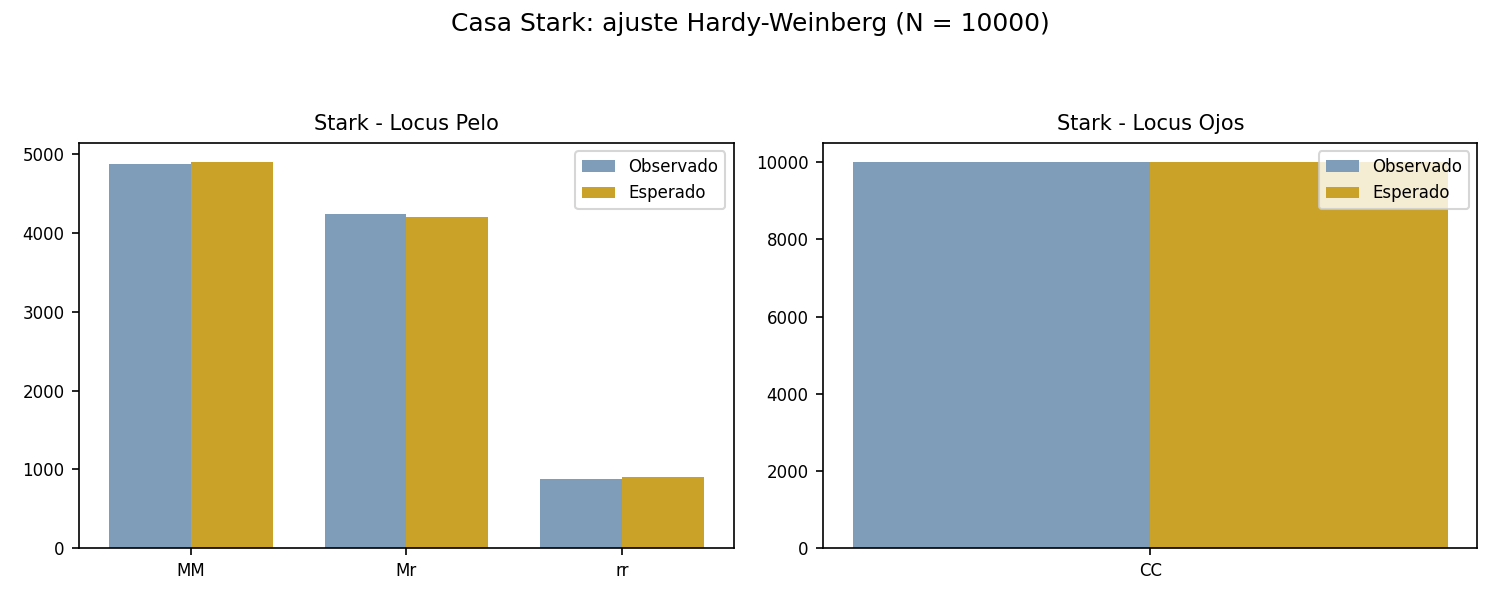

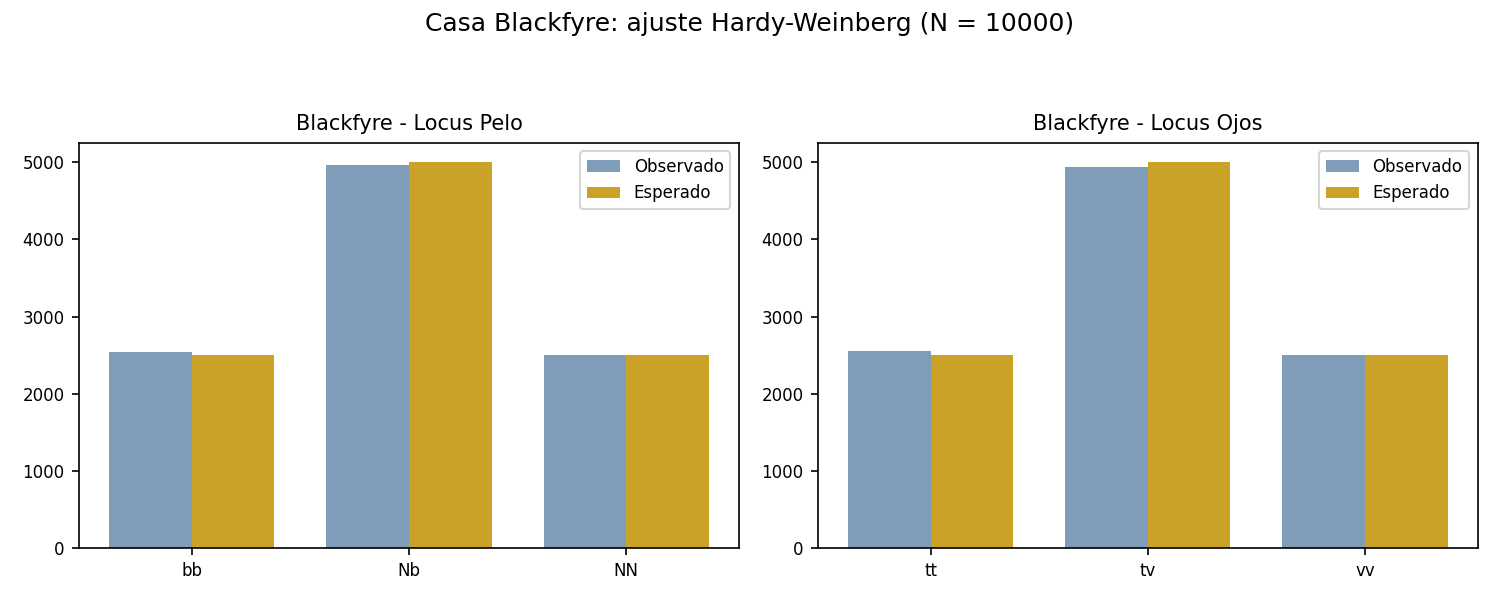

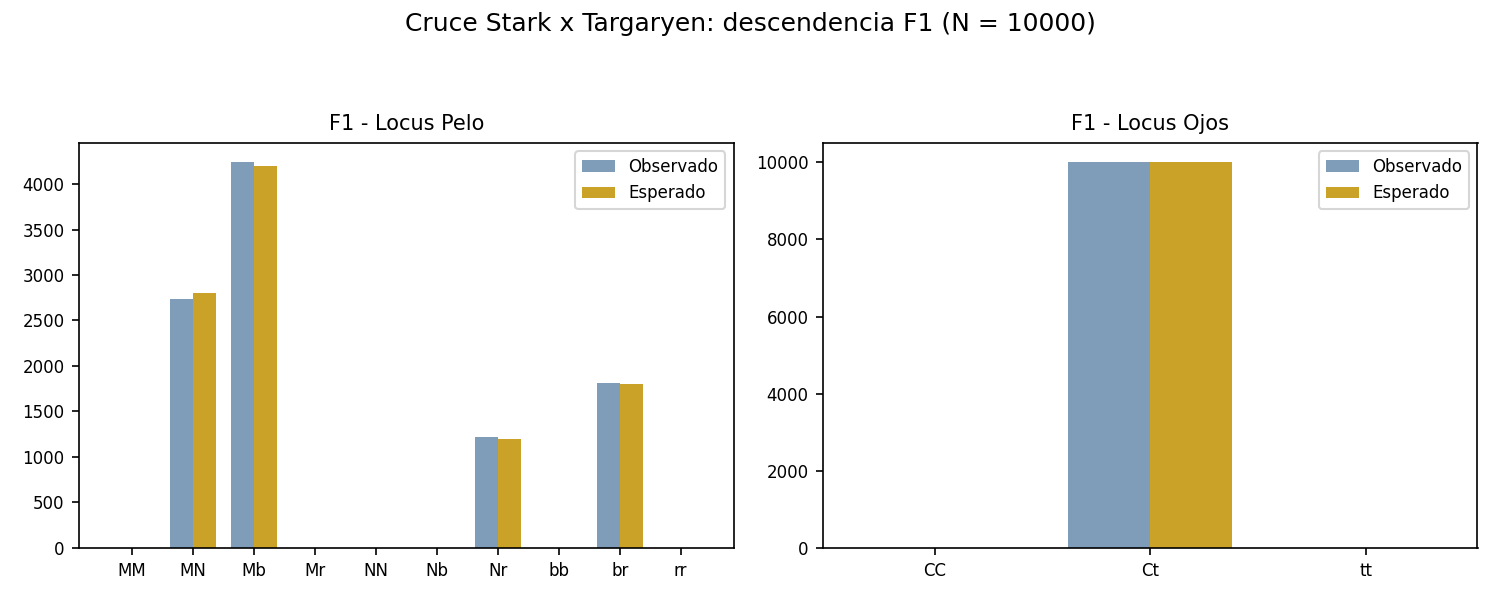

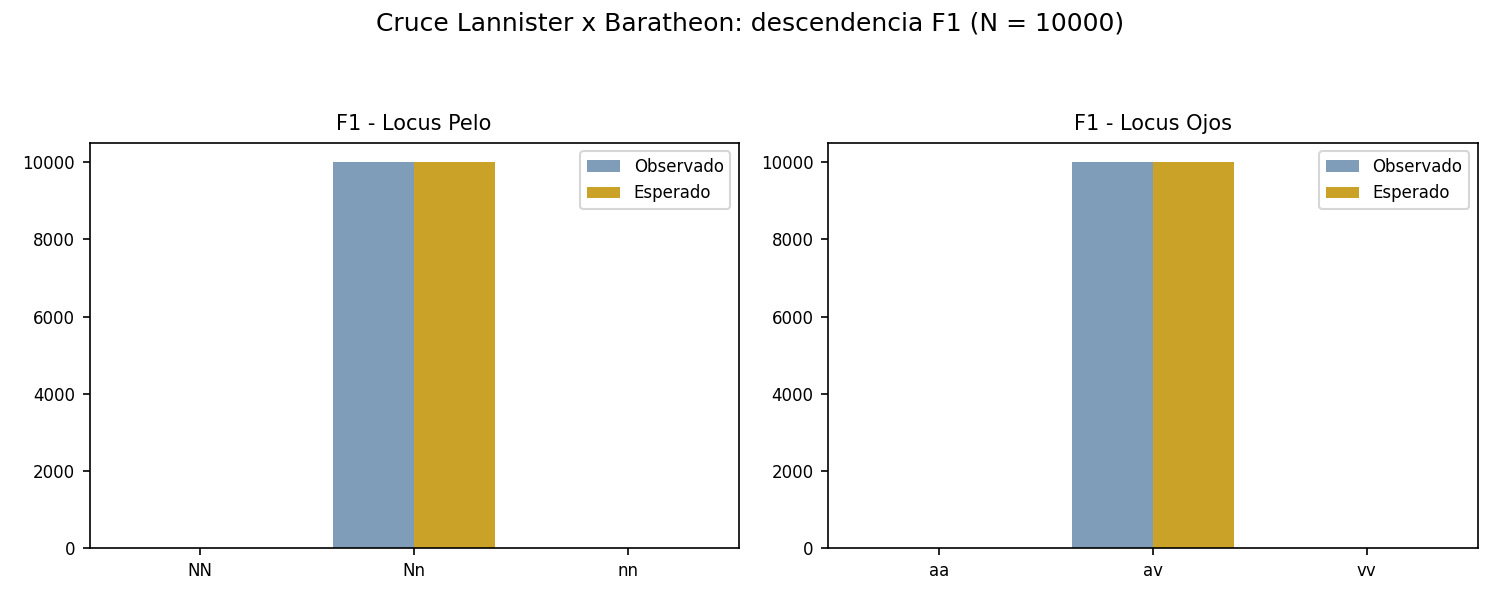

In [ ]:
from IPython.display import Image, display

for archivo in ["grafico_stark_hw.png", "grafico_blackfyre_hw.png",
                "grafico_stark_targaryen_f1.png",
                "grafico_lannister_baratheon_f1.png"]:
    display(Image(filename=archivo))